In [32]:
import json
import re
from konlpy.tag import Okt
from kiwipiepy import Kiwi
from collections import Counter
import matplotlib.pyplot as plt
from matplotlib import font_manager, rc
from wordcloud import WordCloud
import pandas as pd
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import matplotlib
import numpy as np
import warnings
import matplotlib
warnings.filterwarnings(action='ignore')
import folium

In [ ]:
#인구 대비 공공도서관 수
library = pd.read_csv('9장_data/NL_PUBLIC_LBRRY_PER_AVRG_POPLTN_CO_LIST_202105.csv')
library.head() #작업 확인용 출력

,ANALS_TRGET_YEAR,ANALS_TRGET_MT,ONE_AREA_NM,TWO_AREA_NM,PUBLIC_LBRRY_CO,POPLTN_CO,AVRG_POPLTN_CO
0,2021,1,강원도,강릉시,4,213412,53353.00
1,2021,1,강원도,고성군,3,26687,8895.67
2,2021,1,강원도,동해시,3,90416,30138.67
3,2021,1,강원도,삼척시,3,64946,21648.67
4,2021,1,강원도,속초시,3,82652,27550.67


In [ ]:
#컬럼명 변경
library = library.rename(columns = {'ONE_AREA_NM': '시도', 'TWO_AREA_NM': '군구', 'PUBLIC_LBRRY_CO': '도서관수'})
library['군구'] = library['군구'].str.strip()
#시도군구 컬럼 만들기
library['시도군구'] = library.apply(lambda r: r['시도']+' '+r['군구'],axis = 1)
library.head(1)

,ANALS_TRGET_YEAR,ANALS_TRGET_MT,시도,군구,도서관수,POPLTN_CO,AVRG_POPLTN_CO,시도군구
0,2021,1,강원도,강릉시,4,213412,53353.0,강원도 강릉시


In [4]:
# 주소에서 시도, 군구 정보 분리
addr = pd.DataFrame({'시도': library['시도'], '군구': library['군구'], '도서관수': library['도서관수'] })
addr.head() #작업 확인용 출력

,시도,군구,도서관수
0,강원도,강릉시,4
1,강원도,고성군,3
2,강원도,동해시,3
3,강원도,삼척시,3
4,강원도,속초시,3


In [5]:
addr['시도군구'] = addr.apply(lambda r: r['시도'] + ' ' + r['군구'], axis = 1)
addr['count'] = 0
addr.head()

,시도,군구,도서관수,시도군구,count
0,강원도,강릉시,4,강원도 강릉시,0
1,강원도,고성군,3,강원도 고성군,0
2,강원도,동해시,3,강원도 동해시,0
3,강원도,삼척시,3,강원도 삼척시,0
4,강원도,속초시,3,강원도 속초시,0


In [6]:
# as_index = False -> groupby는 그룹 컬럼을 인덱스로 삼는데 일반 인덱스를 사용하겠다는 의미
# addr = addr.reset_index(drop=True)
addr_group = pd.DataFrame( addr.groupby(['시도', '군구', '시도군구', '도서관수'], as_index = False).count())
addr_group.head(3) #작업 확인용 출력

,시도,군구,시도군구,도서관수,count
0,강원도,강릉시,강원도 강릉시,4,4
1,강원도,고성군,강원도 고성군,3,4
2,강원도,동해시,강원도 동해시,3,4


In [7]:
library = library.set_index("시도군구")
library.head(1)

,ANALS_TRGET_YEAR,ANALS_TRGET_MT,시도,군구,도서관수,POPLTN_CO,AVRG_POPLTN_CO
시도군구,,,,,,,
강원도 강릉시,2021,1,강원도,강릉시,4,213412,53353.0


In [8]:
addr_library_merge = pd.merge(addr_group, library, how='inner', on='시도군구')
addr_library_merge.head()

,시도_x,군구_x,시도군구,도서관수_x,count,ANALS_TRGET_YEAR,ANALS_TRGET_MT,시도_y,군구_y,도서관수_y,POPLTN_CO,AVRG_POPLTN_CO
0,강원도,강릉시,강원도 강릉시,4,4,2021,1,강원도,강릉시,4,213412,53353.00
1,강원도,강릉시,강원도 강릉시,4,4,2021,2,강원도,강릉시,4,213231,53307.75
2,강원도,강릉시,강원도 강릉시,4,4,2021,3,강원도,강릉시,4,212909,53227.25
3,강원도,강릉시,강원도 강릉시,4,4,2021,4,강원도,강릉시,4,212890,53222.50
4,강원도,고성군,강원도 고성군,3,4,2021,1,강원도,고성군,3,26687,8895.67


In [9]:
local_MC_library = addr_library_merge[['시도_x', '군구_x','도서관수_x', 'count', 'POPLTN_CO']]
local_MC_library.head(1) #작업 확인용 출력

,시도_x,군구_x,도서관수_x,count,POPLTN_CO
0,강원도,강릉시,4,4,213412


In [ ]:
local_MC_library = local_MC_library.rename(columns= {'시도_x' : '시도','군구_x' : '군구','도서관수_x': '도서관수', 'POPLTN_CO' : '인구수'})
lc_count = local_MC_library['count']
#인구수 대비 공공도서관수 비율컬럼 만들기
local_MC_library['MC_ratio'] = lc_count.div(local_MC_library['인구수'], axis = 0)*100000
local_MC_library.head(2)
local_MC_library['시도별']=local_MC_library.groupby('시도',as_index=False)['도서관수'].transform('mean')

In [11]:
from matplotlib import pyplot as plt
from matplotlib import rcParams, style
style.use('ggplot')

from matplotlib import font_manager, rc
font_name = font_manager.FontProperties( fname = "c:/Windows/Fonts/malgun.ttf").get_name()
rc('font', family = font_name)
import os
path = os.getcwd()

In [12]:
data_draw_korea = pd.read_csv(path+'\\9장_data\\data_draw_korea.csv', index_col = 0, encoding = 'UTF-8', engine = 'python')
data_draw_korea.head(3) #작업 확인용 출력

,인구수,shortName,x,y,면적,광역시도,행정구역
0,202520,강릉,11,4,1040.07,강원도,강릉시
1,25589,고성(강원),9,0,664.19,강원도,고성군
2,86747,동해,11,5,180.01,강원도,동해시


In [13]:
#2023년 6월 이후에 변경된 행정구역명으로 수정하기
addr_aliases = { '강원도':'강원특별자치도', '전라북도':'전북특별자치도'}
data_draw_korea['광역시도'] = data_draw_korea['광역시도'].apply(lambda v: addr_aliases.get(v, v))
data_draw_korea.head(3) #작업 확인용 출력

,인구수,shortName,x,y,면적,광역시도,행정구역
0,202520,강릉,11,4,1040.07,강원특별자치도,강릉시
1,25589,고성(강원),9,0,664.19,강원특별자치도,고성군
2,86747,동해,11,5,180.01,강원특별자치도,동해시


In [14]:
data_draw_korea['시도군구'] = data_draw_korea.apply(lambda r: r['광역시도'] + ' ' + r['행정구역'], axis = 1)

In [15]:
data_draw_korea = data_draw_korea.set_index("시도군구")

data_draw_korea.head() #작업 확인용 출력

,인구수,shortName,x,y,면적,광역시도,행정구역
시도군구,,,,,,,
강원특별자치도 강릉시,202520,강릉,11,4,1040.07,강원특별자치도,강릉시
강원특별자치도 고성군,25589,고성(강원),9,0,664.19,강원특별자치도,고성군
강원특별자치도 동해시,86747,동해,11,5,180.01,강원특별자치도,동해시
강원특별자치도 삼척시,63986,삼척,11,8,1185.80,강원특별자치도,삼척시
강원특별자치도 속초시,76733,속초,9,1,105.25,강원특별자치도,속초시


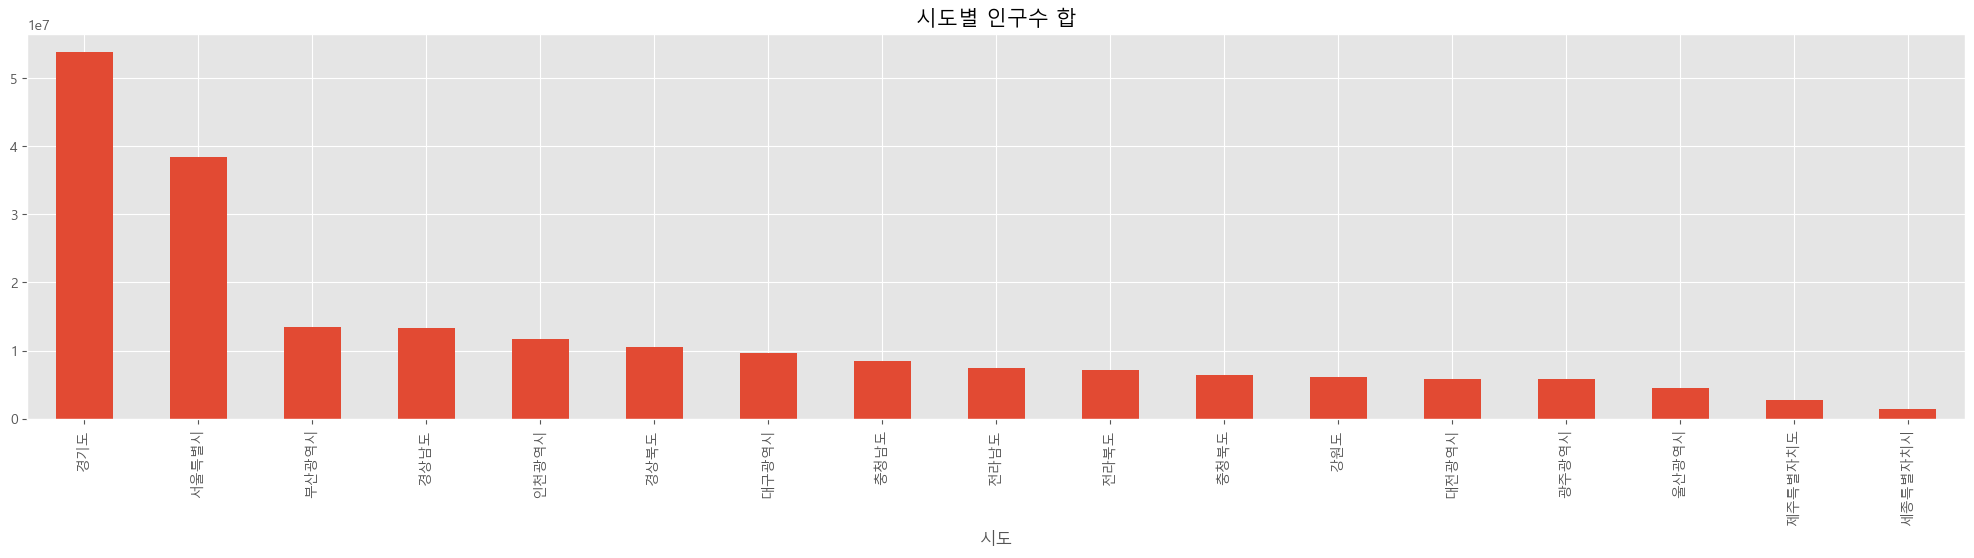

In [ ]:
new_library = local_MC_library.groupby('시도')['인구수'].sum()
new_library = new_library.sort_values(ascending = False)
plt.rcParams["figure.figsize"] = (25, 5)
new_library.plot(kind = 'bar', rot = 90)
plt.title('시도별 인구수 합', fontsize=15)
plt.show()
#경기도, 서울특별시, 부산광역시 순으로 인구수가 많다

In [17]:
local_MC_library.groupby('시도')[['도서관수','인구수']].sum().sort_values('도서관수',ascending=False)

,도서관수,인구수
시도,,
경기도,1140,53866892
서울특별시,760,38493770
경상남도,292,13334527
전라남도,284,7389329
경상북도,276,10545845
충청남도,252,8471654
전라북도,252,7197848
강원도,236,6155145
인천광역시,228,11756832


In [18]:
local_MC_library.groupby('시도')[['도서관수','인구수']].sum().sort_values('인구수',ascending=False)

,도서관수,인구수
시도,,
경기도,1140,53866892
서울특별시,760,38493770
부산광역시,188,13519252
경상남도,292,13334527
인천광역시,228,11756832
경상북도,276,10545845
대구광역시,172,9644175
충청남도,252,8471654
전라남도,284,7389329


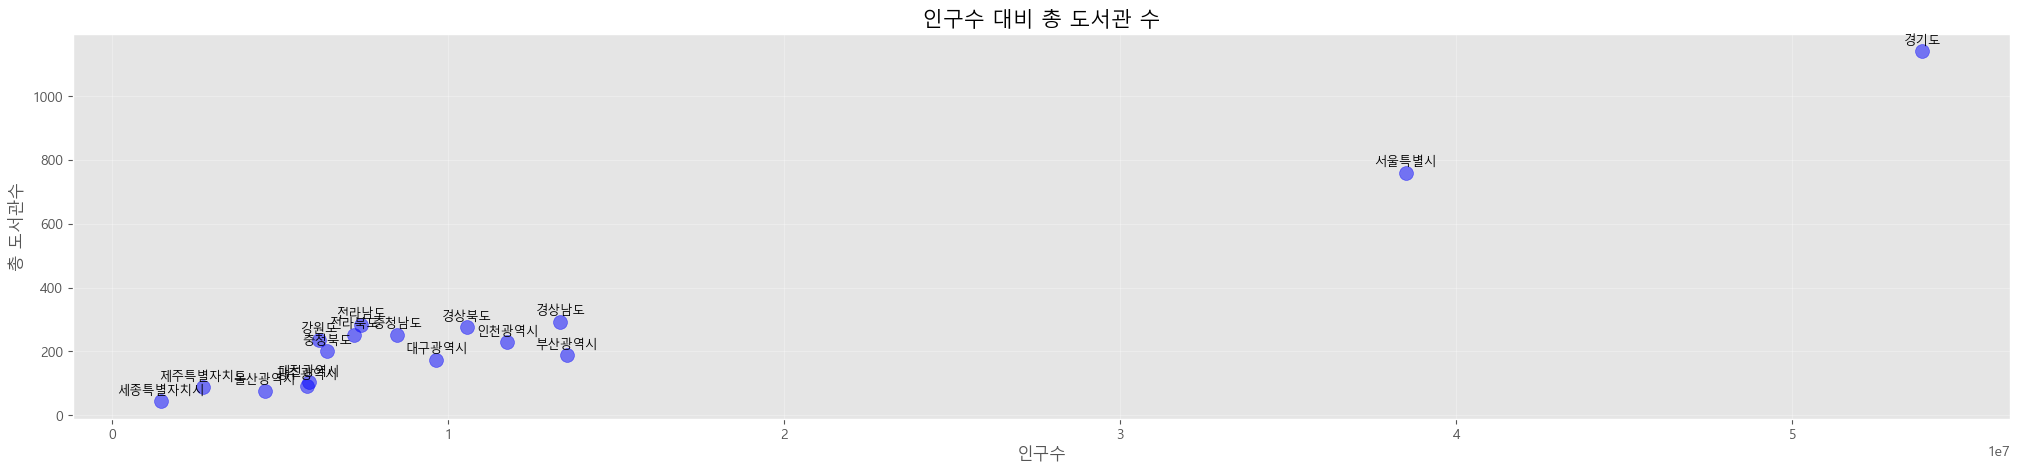

In [19]:
scatter_library = local_MC_library.groupby('시도')[['인구수','도서관수']].sum().reset_index()
plt.scatter(scatter_library['인구수'], scatter_library['도서관수'], s=100, color='blue', alpha=0.5)
plt.rcParams["figure.figsize"] = (25, 5)
for i, txt in enumerate(scatter_library['시도']):
    offset = scatter_library['도서관수'].max() * 0.02
    plt.text(scatter_library['인구수'].iloc[i], scatter_library['도서관수'].iloc[i] + offset, 
             txt, fontsize=9, ha='center', color='black')
plt.title('인구수 대비 총 도서관 수', fontsize=15)
plt.xlabel('인구수', fontsize=12)
plt.ylabel('총 도서관수', fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()

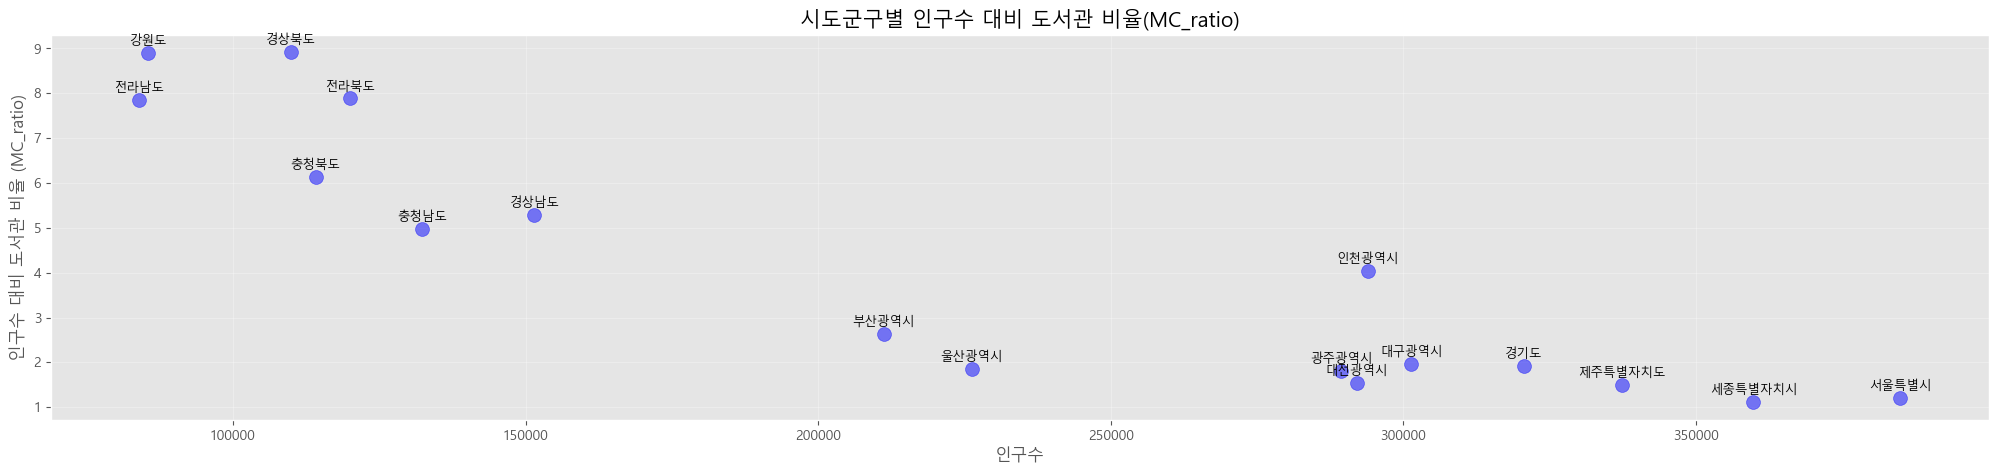

In [20]:
scatter_library = local_MC_library.groupby('시도')[['인구수','MC_ratio']].mean().reset_index()
plt.scatter(scatter_library['인구수'], scatter_library['MC_ratio'], s=100, color='blue', alpha=0.5)
plt.rcParams["figure.figsize"] = (25, 5)
for i, txt in enumerate(scatter_library['시도']):
    offset = scatter_library['MC_ratio'].max() * 0.02
    plt.text(scatter_library['인구수'].iloc[i], scatter_library['MC_ratio'].iloc[i] + offset, 
             txt, fontsize=9, ha='center', color='black')
plt.title('시도군구별 인구수 대비 도서관 비율(MC_ratio)', fontsize=15)
plt.xlabel('인구수', fontsize=12)
plt.ylabel('인구수 대비 도서관 비율 (MC_ratio)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()

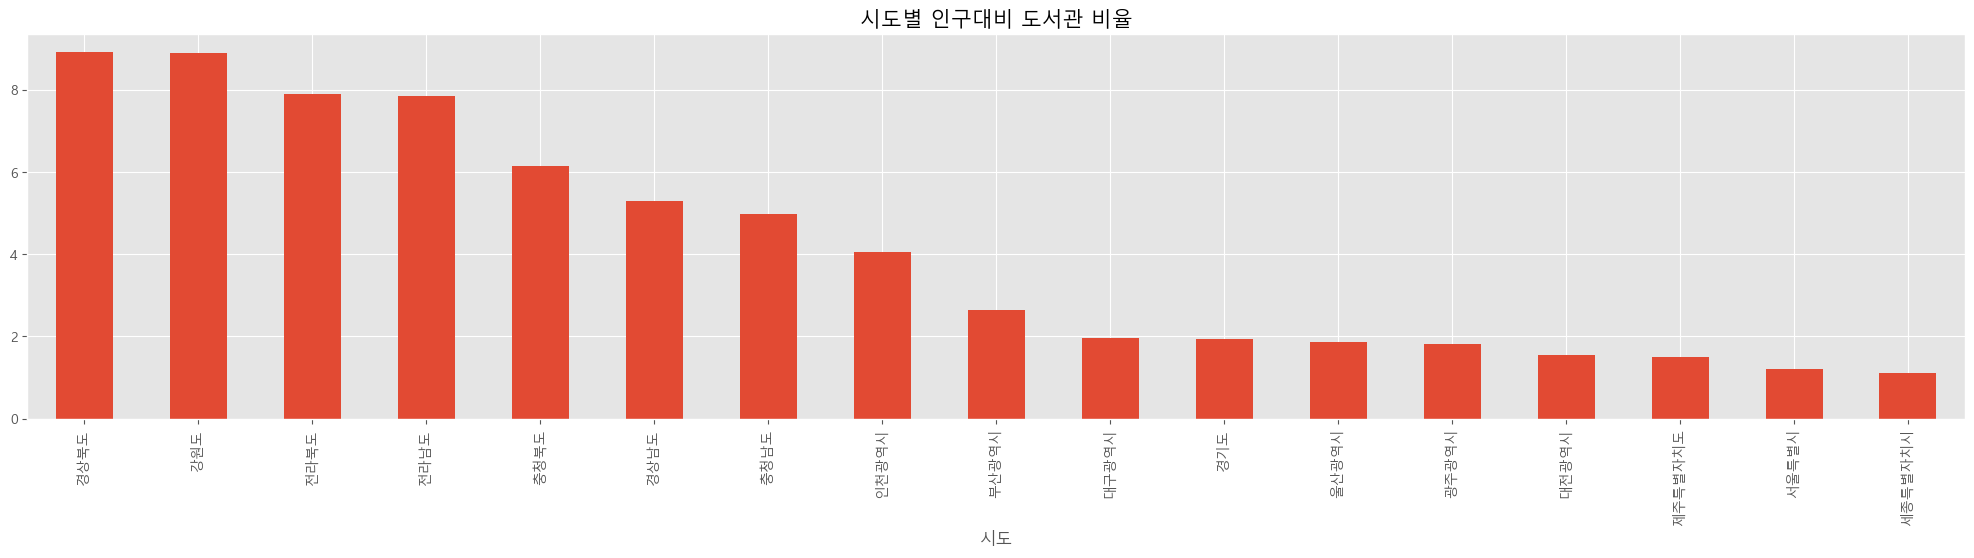

In [21]:
new_library = local_MC_library.groupby('시도')['MC_ratio'].mean()
new_library.head(2)
new_library = new_library.sort_values(ascending = False)
plt.rcParams["figure.figsize"] = (25, 5)
new_library.plot(kind = 'bar', rot = 90)
plt.title('시도별 인구대비 도서관 비율', fontsize=15)
plt.show()

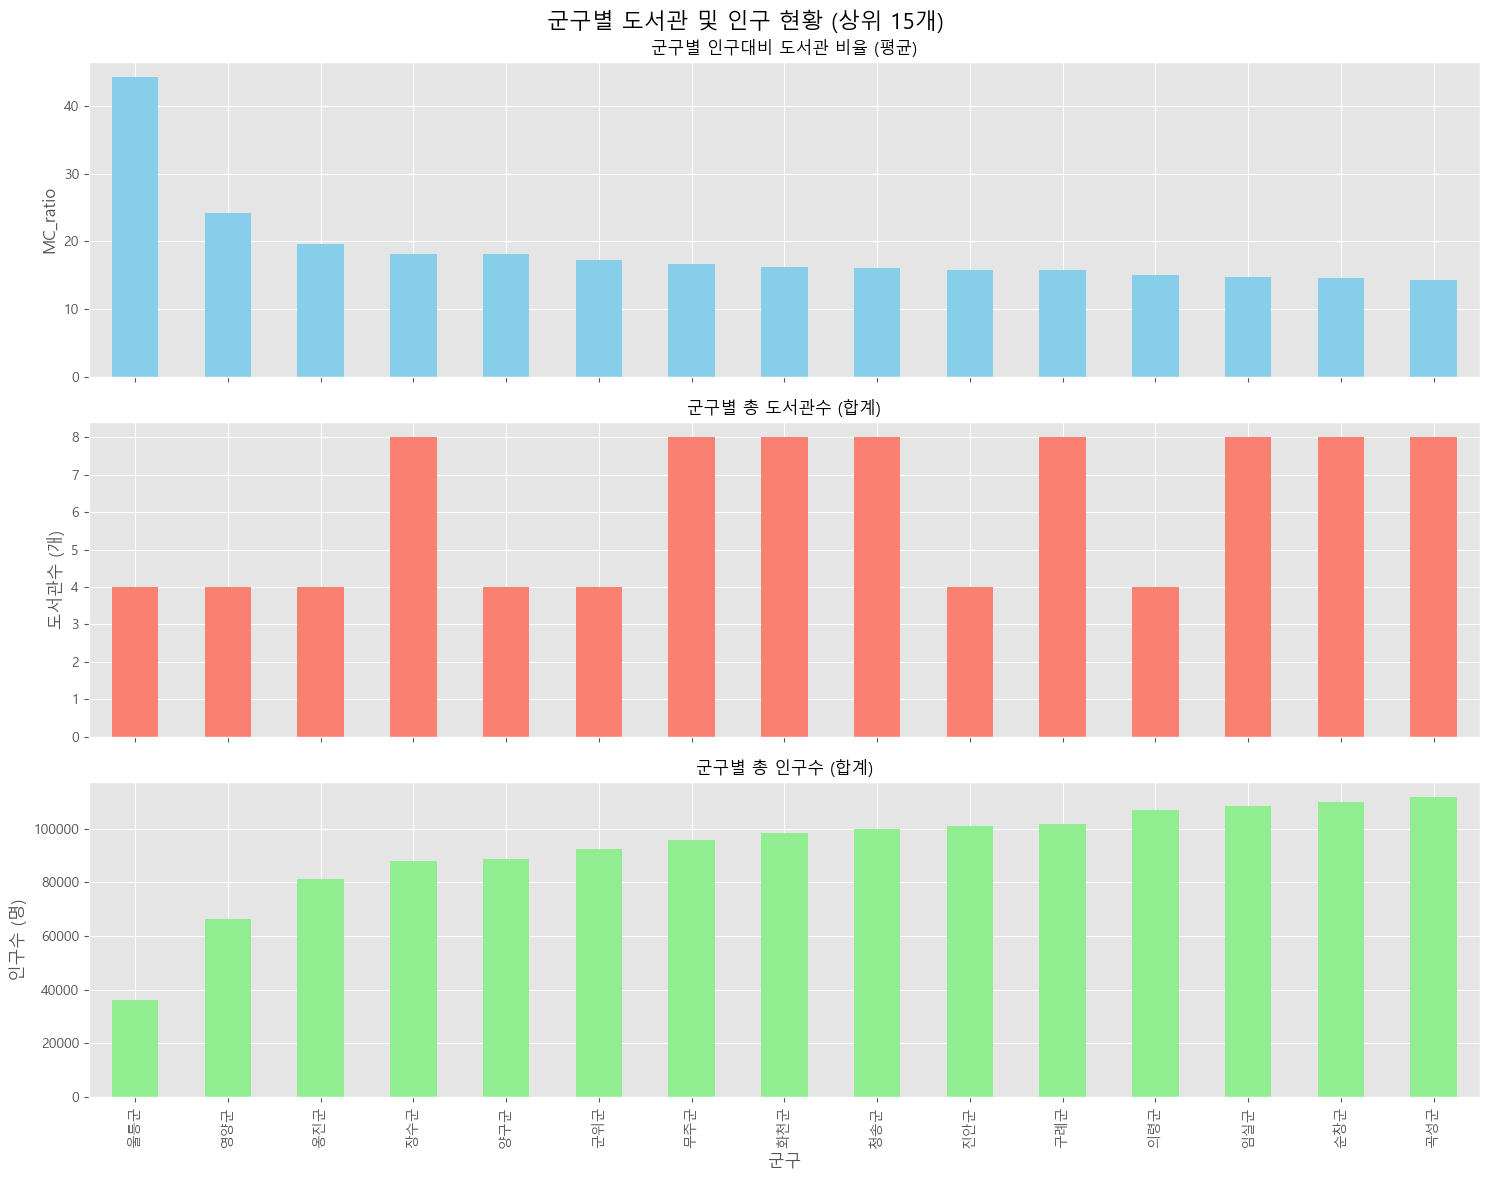

In [22]:
new_library = local_MC_library.groupby('군구').agg({
    '인구수': 'sum',
    '도서관수': 'sum',
    'MC_ratio': 'mean'
})

new_library = new_library.sort_values('MC_ratio', ascending=False).head(15)


fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)

new_library['MC_ratio'].plot(kind='bar', ax=axes[0], color='skyblue', rot=90)
axes[0].set_title('군구별 인구대비 도서관 비율 (평균)', fontsize=12)
axes[0].set_ylabel('MC_ratio')

new_library['도서관수'].plot(kind='bar', ax=axes[1], color='salmon', rot=90)
axes[1].set_title('군구별 총 도서관수 (합계)', fontsize=12)
axes[1].set_ylabel('도서관수 (개)')


new_library['인구수'].plot(kind='bar', ax=axes[2], color='lightgreen', rot=90)
axes[2].set_title('군구별 총 인구수 (합계)', fontsize=12)
axes[2].set_ylabel('인구수 (명)')


plt.suptitle('군구별 도서관 및 인구 현황 (상위 15개)', fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

In [23]:
data_draw_korea_MC_library_all = pd.merge(data_draw_korea,local_MC_library, how = 'outer', 
                                             left_on='행정구역', right_on = '군구')
data_draw_korea_MC_library_all.head(3)

,인구수_x,shortName,x,y,면적,광역시도,행정구역,시도,군구,도서관수,count,인구수_y,MC_ratio,시도별
0,53497.0,가평,9.0,3.0,843.04,경기도,가평군,경기도,가평군,4.0,4.0,62399.0,6.410359,6.785714
1,53497.0,가평,9.0,3.0,843.04,경기도,가평군,경기도,가평군,4.0,4.0,62339.0,6.416529,6.785714
2,53497.0,가평,9.0,3.0,843.04,경기도,가평군,경기도,가평군,4.0,4.0,62049.0,6.446518,6.785714


In [24]:
BORDER_LINES = [
    [(3, 2), (5, 2), (5, 3), (9, 3), (9, 1)], # 인천
    [ (2, 5), (3, 5), (3, 4), (8, 4), (8, 7), (7, 7), (7, 9), (4, 9),
    (4, 7), (1, 7)], # 서울
    [(1, 6), (1, 9), (3, 9), (3, 10), (8, 10), (8, 9),
    (9, 9), (9, 8), (10, 8), (10, 5), (9, 5), (9, 3)], # 경기도
    [(9, 12), (9, 10), (8, 10)], # 강원도
    [(10, 5), (11, 5), (11, 4), (12, 4), (12, 5), (13, 5),
    (13, 4), (14, 4), (14, 2)], # 충청남도
    [(11, 5), (12, 5), (12, 6), (15, 6), (15, 7), (13, 7),
    (13, 8), (11, 8), (11, 9), (10, 9), (10, 8)], # 충청북도
    [(14, 4), (15, 4), (15, 6)], # 대전시
    [(14, 7), (14, 9), (13, 9), (13, 11), (13, 13)], # 경상북도
    [(14, 8), (16, 8), (16, 10), (15, 10),
    (15, 11), (14, 11), (14, 12), (13, 12)], # 대구시
    [(15, 11), (16, 11), (16, 13)], # 울산시
    [(17, 1), (17, 3), (18, 3), (18, 6), (15, 6)], # 전라북도
    [ (19, 2), (19, 4), (21, 4), (21, 3), (22, 3), (22, 2), (19, 2)], #광주시
    [(18, 5), (20, 5), (20, 6)], # 전라남도
    [ (16, 9), (18, 9), (18, 8), (19, 8), (19, 9), (20, 9), (20, 10)], #부산시
]

In [25]:
def draw_blockMap(blockedMap, targetData, title, color):
    whitelabelmin = ( max(blockedMap[targetData]) - min(blockedMap[targetData])) * 0.25 + min(blockedMap[targetData])
    datalabel = targetData
    vmin = min(blockedMap[targetData])
    vmax = max(blockedMap[targetData])
    mapdata = blockedMap.pivot(index = 'y', columns = 'x', values = targetData)
    masked_mapdata = np.ma.masked_where(np.isnan(mapdata), mapdata)
    
    plt.figure(figsize = (8, 13))
    plt.title(title)
    plt.pcolor( masked_mapdata, vmin = vmin, vmax = vmax, cmap = color, edgecolor = '#aaaaaa', linewidth = 0.5)
    #지역 이름 표시
    for idx, row in blockedMap.iterrows():
        annocolor = 'white' if row[targetData] > whitelabelmin else 'black'
        #광역시는 구 이름이 겹치는 경우가 많아서 시단위 이름도 같이 표시
        if row['광역시도'].endswith('시') and not row['광역시도'].startswith('세종'):
            dispname = ' {}\n{}'.format(row['광역시도'][:2], row['행정구역'][:-1])
            if len(row['행정구역']) <= 2:
                dispname += row['행정구역'][-1]
        else:
            dispname = row['행정구역'][:-1]
            
        #서대문구, 서귀포시 같이 이름이 3자 이상이면 작은 글자로 표시
        if len(dispname.splitlines()[-1]) >= 3:
            fontsize, linespacing = 9.5, 1.5
        else:
            fontsize, linespacing = 11, 1.2
            
            plt.annotate(dispname, (row['x']+0.5, row['y']+0.5), weight = 'bold',fontsize = fontsize, 
                         ha = 'center', va = 'center', color = annocolor, linespacing = linespacing)

    #시도 경계를 그린다.
    for path in BORDER_LINES:
        ys, xs = zip(*path)
        plt.plot(xs, ys, c = 'black', lw = 4)
        
    plt.gca().invert_yaxis()
    #plt.gca().set_aspect(1)
    plt.axis('off')
    
    cb = plt.colorbar(shrink = 1, aspect = 10)
    cb.set_label(datalabel)
    
    plt.tight_layout()
    plt.savefig('.\\9장_data\\' + 'blockMap_' + targetData + '.png')
    plt.show()

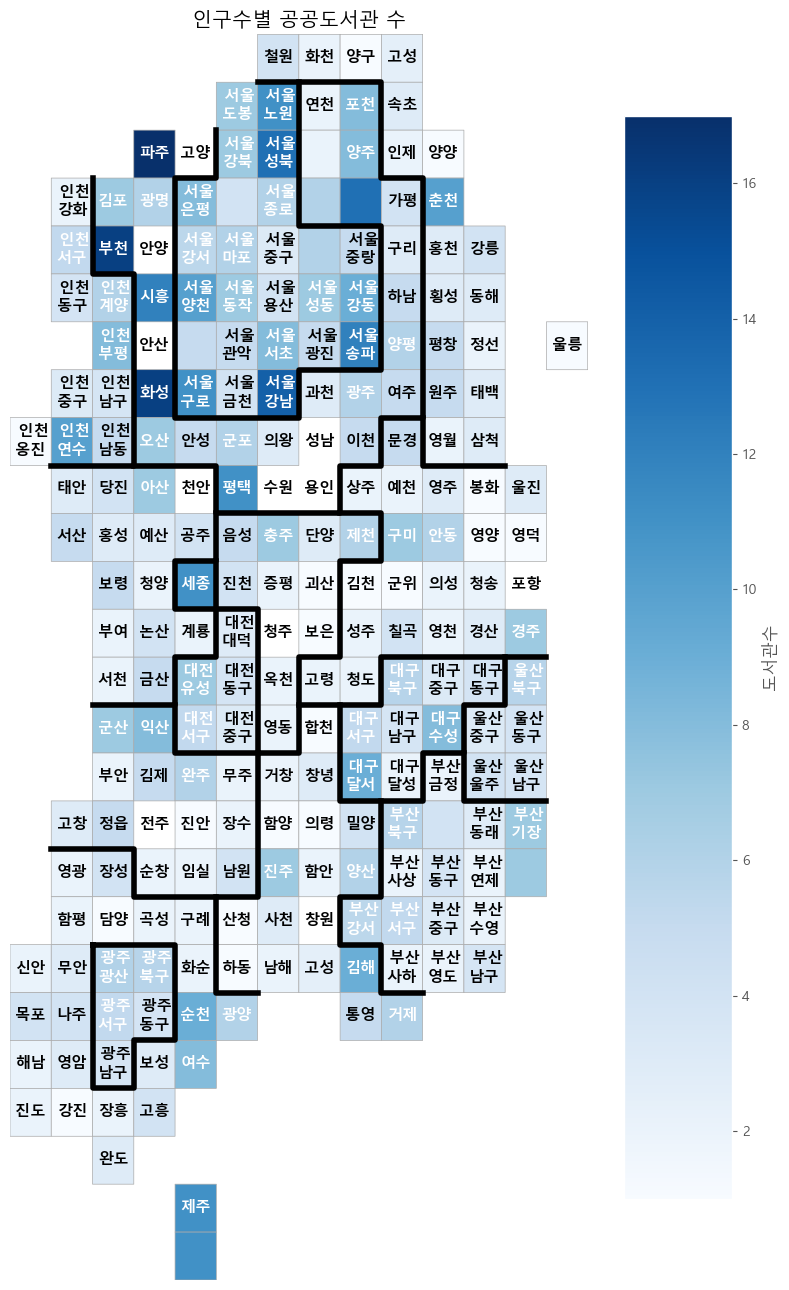

In [26]:
data_draw_korea_MC_library_all = data_draw_korea_MC_library_all.reset_index().groupby(['x', 'y', '광역시도', '행정구역'], as_index=False)['도서관수'].mean(numeric_only=True)
data_draw_korea_MC_library_all = data_draw_korea_MC_library_all.dropna(subset=['x', 'y'])
draw_blockMap(data_draw_korea_MC_library_all, '도서관수', '인구수별 공공도서관 수', 'Blues')

     인구수_x shortName    x    y      면적 광역시도 행정구역   시도   군구  도서관수  count  \
0  53497.0        가평  9.0  3.0  843.04  경기도  가평군  경기도  가평군   4.0    4.0   

     인구수_y  MC_ratio       시도별  
0  62399.0  6.410359  6.785714  


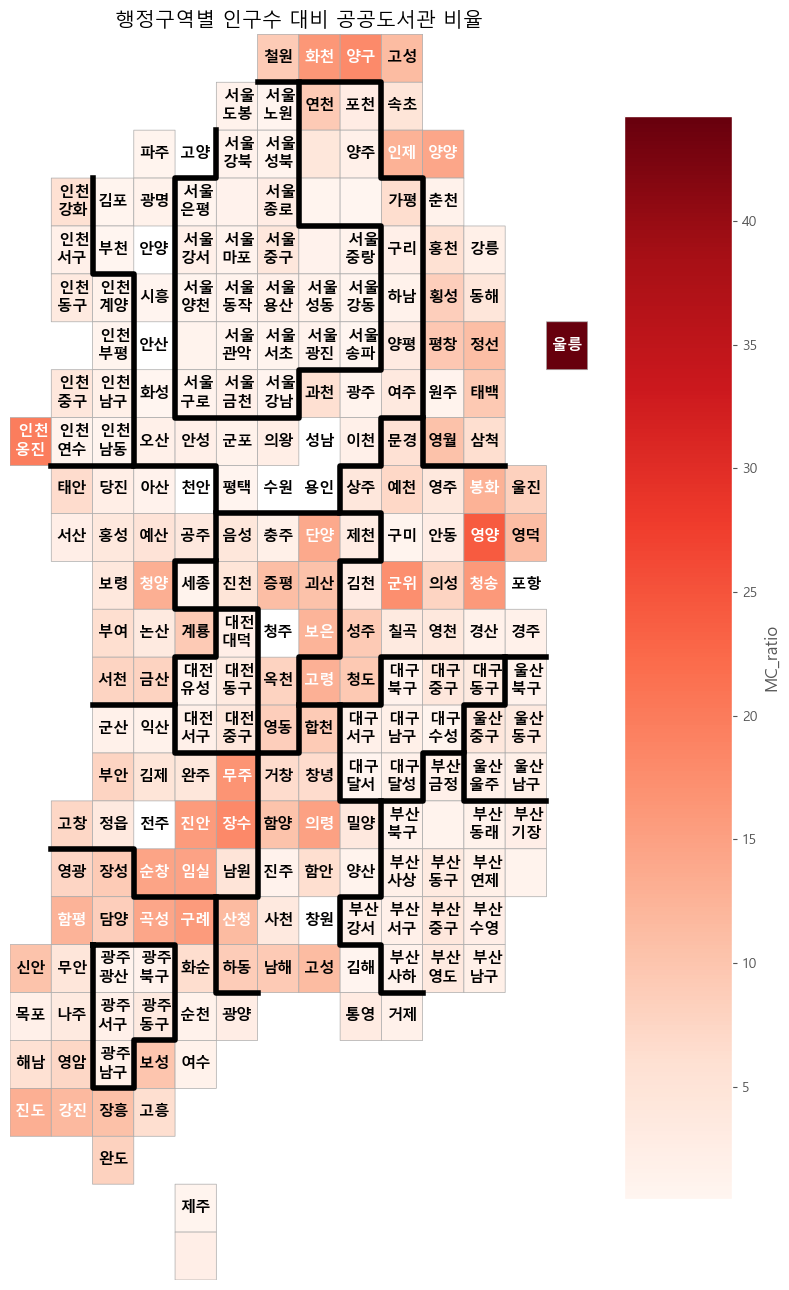

In [51]:
data_draw_korea_MC_library_all = pd.merge(data_draw_korea,local_MC_library, how = 'outer', 
                                             left_on='행정구역', right_on = '군구')
print(data_draw_korea_MC_library_all.head(1))
data_draw_korea_MC_library_all = data_draw_korea_MC_library_all.reset_index().groupby(['x', 'y', '광역시도', '행정구역'], as_index=False)['MC_ratio'].mean(numeric_only=True)
data_draw_korea_MC_library_all = data_draw_korea_MC_library_all.dropna(subset=['x', 'y'])
draw_blockMap( data_draw_korea_MC_library_all, 'MC_ratio', '행정구역별 인구수 대비 공공도서관 비율', 'Reds')

In [30]:
CB_geoData = pd.read_csv('9장_data/library.csv', encoding = 'utf8', engine = 'python')

In [31]:
CB_geoData.head()

,field1,store,adress,field4,field5,field6,field7,field8,field9,field10,...,field30,field31,field32,field33,field34,_GC_TYPE,_CLEANADDR,_PNU,_X,_Y
0,1500,포천시립중앙도서관,경기도 포천시 신북면 중앙로207번길 26,37.905303,127.206376,경기도,포천시,141333.0,141333.0,031-538-3911,...,포천시립중앙도서관,Y,경기도,포천시,동두천,정,경기도 포천시 중앙로207번길 26 (신북면),4.165030e+18,127.206422,37.905266
1,1501,포천시립소흘도서관,경기도 포천시 소흘읍 송우로 101-29,37.829605,127.137534,경기도,포천시,141172.0,141172.0,031-538-3952,...,소흘도서관,N,경기도,포천시,동두천,정,경기도 포천시 송우로 101-29 (소흘읍),4.165030e+18,127.137607,37.829658
2,1502,포천시립일동도서관,경기도 포천시 일동면 화동로 1021,37.954936,127.315456,경기도,포천시,141094.0,141094.0,031-538-3932,...,일동도서관,N,경기도,포천시,동두천,정,경기도 포천시 화동로 1021 (일동면),4.165040e+18,127.315529,37.954910
3,1504,포천시립영북도서관,경기도 포천시 영북면 운천안길 3,38.087682,127.274170,경기도,포천시,141520.0,141520.0,031-538-3972,...,영북도서관,N,경기도,포천시,동두천,정,경기도 포천시 운천안길 3 (영북면),4.165040e+18,127.274224,38.087755
4,2200,통영시립도서관,경상남도 통영시 무전3길 29,34.861820,128.424713,경상남도,통영시,148100.0,148100.0,055-650-2630,...,통영시립도서관,Y,경상남도,통영시,통영,정,경상남도 통영시 무전3길 29 (무전동),4.822010e+18,128.424711,34.861507


In [46]:
#할리스 위치
map_li = folium.Map(location = [37.550971, 126.960395], zoom_start = 15, tiles='Esri WorldImagery')
for i, store in CB_geoData.iterrows():
    folium.Marker( location = [store['_Y'], store['_X']], popup = store['store'],
                  tooltip = store['store'], 
                   icon = folium.Icon(color = 'green',
                                     icon = 'check', prefix='fa')).add_to(map_li)

In [47]:
map_li.save('9장_data/map_li.html')

In [53]:
# import json
# import urllib.request
# import folium
# import pandas as pd

# # 한국 시군구 경계 지도 파일 다운로드
# geo_url = 'https://raw.githubusercontent.com/southkorea/southkorea-maps/master/kostat/2013/json/skorea_municipalities_geo_simple.json'
# geo_path = './9장_data/skorea_municipalities_geo_simple.json'

# urllib.request.urlretrieve(geo_url, geo_path)

# with open(geo_path, encoding='utf-8') as f:
#     korea_geo = json.load(f)

# # GeoJSON의 행정구역 코드 앞 2자리로 광역시도 이름 붙이기
# sido_map = {
#     '11': '서울특별시',
#     '21': '부산광역시',
#     '22': '대구광역시',
#     '23': '인천광역시',
#     '24': '광주광역시',
#     '25': '대전광역시',
#     '26': '울산광역시',
#     '29': '세종특별자치시',
#     '31': '경기도',
#     '32': '강원도',
#     '33': '충청북도',
#     '34': '충청남도',
#     '35': '전북특별자치도',
#     '36': '전라남도',
#     '37': '경상북도',
#     '38': '경상남도',
#     '39': '제주특별자치도'
# }

# for feature in korea_geo['features']:
#     code = feature['properties']['code']
#     sido = sido_map.get(code[:2])
#     name = feature['properties']['name']
#     feature['properties']['지역'] = sido + ' ' + name

# # blockedMap에도 GeoJSON과 맞출 지역 이름 만들기
# data_draw_korea_MC_library_all['지역'] = data_draw_korea_MC_library_all['광역시도'] + ' ' + data_draw_korea_MC_library_all['행정구역']

# # 시각화할 컬럼명
# targetData = '도서관수'   # 여기를 원하는 컬럼명으로 바꾸면 됨

# m = folium.Map(
#     location=[36.4, 127.8],
#     zoom_start=7,
#     tiles='CartoDB positron'
# )

# folium.Choropleth(
#     geo_data=korea_geo,
#     data=data_draw_korea_MC_library_all,
#     columns=['지역', targetData],
#     key_on='feature.properties.지역',
#     fill_color='YlOrRd',
#     fill_opacity=0.8,
#     line_opacity=0.5,
#     legend_name='지역별 병원 수'
# ).add_to(m)

# m